# Barnard 68. Morpho-kinematic Evolution and Spline Analysis

**Author:** Margarita Tsvetkova \
**Mentor:** Alexei Baigashov, astrophysics laboratory of the Immanuel Kant Baltic Federal University (IKBFU) \
**Course:** Data Analytics in Python, final paper \
**Date:** September 2024


## 0. Setup

The analysis uses NumPy, SciPy and Matplotlib, with `contourpy` for the iso-contours.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import animation
from matplotlib.colors import LogNorm
from scipy import ndimage
from scipy.interpolate import (splprep, splev, UnivariateSpline, CubicSpline,
                               make_smoothing_spline, RBFInterpolator)
import contourpy
from IPython.display import Image, display

plt.rcParams.update({"figure.dpi": 110, "axes.grid": False, "font.size": 10,
                     "image.origin": "lower"})



# Units used: length [pc], velocity [km/s], time [Myr], mass [Msun]
G   = 4.30091e-3     # pc (km/s)^2 / Msun
KMS = 1.022712       # 1 km/s expressed in pc/Myr
SIGMA_TO_AV = 4.46e19 / 9.4e20   # (Msun/pc^2 -> N(H2) with mu=2.8) / (N(H2) per mag of A_V)

## 1. Introduction

Alves, Lada & Lada (2001) measured the column density of Barnard 68 from the extinction of background stars and found that its radial profile matches a Bonnor-Ebert sphere (Ebert 1955; Bonnor 1956). The fit gives $\xi_{\max} = 6.9 \pm 0.2$, slightly above the critical value $\xi_{\rm crit} \approx 6.5$, so the globule should be unstable.

Yet B68 looks old and stable. Burkert & Alves (2009) suggest that it is colliding with a smaller core of about $0.2\,M_\odot$, the "prong" on its south-eastern edge, at about $0.37\ \mathrm{km\,s^{-1}}$. In their hydrodynamic simulations the collision triggers collapse, and B68 forms a star within about $2\times10^{5}$ yr.

Here we build a kinematic model of the same scenario in the spirit of SHAPE (Steffen et al. 2011), without pressure, shocks or radiative transfer. The particles are turned into the maps an observer would get, and these maps are then measured with splines.

Assumptions:

* B68 is at $d = 125$ pc, with radius $R_{\rm B68} \approx 12\,500$ AU $= 0.0606$ pc and mass $M_{\rm B68} \approx 2.1\,M_\odot$ (Alves et al. 2001).
* The core and halo have a Bonnor-Ebert profile with $\xi_{\max} = 6.9$. The companion is a smaller, sub-critical Bonnor-Ebert sphere with $\xi_{\max} = 4$.
* All particles have the same mass; their velocities are prescribed (Section 3).
* The lines are optically thin, with width $\sigma_{\rm line} = 0.08\ \mathrm{km\,s^{-1}}$, close to the C$^{18}$O line width measured in B68 by Lada et al. (2003).
* Units: length in pc, velocity in km/s, time in Myr, mass in $M_\odot$. $1\ \mathrm{km\,s^{-1}} = 1.0227\ \mathrm{pc\,Myr^{-1}}$.

### Parameters

| Symbol | Meaning | Value |
|---|---|---|
| $\xi,\;\xi_{\max}$ | dimensionless Bonnor-Ebert radius and its value at the edge | 6.9 (core), 4 (companion) |
| $N,\;m_p$ | number of particles and particle mass $M_{\rm B68}/N$ | 75 676, $2.77\times10^{-5}\,M_\odot$ |
| $w_j$ | Lagrangian weight of particle $j$ | 0 (core) to 1 (companion) |
| $V_{\rm imp}$ | approach speed of the companion | $0.37\ \mathrm{km\,s^{-1}}$ |
| $i$ | inclination of the approach out of the sky plane | $25^\circ$ |
| $t_{\rm imp}$ | moment the companion reaches the edge of the dark core | 69 kyr |
| $\tau_{\rm drag}$ | braking time of the companion after impact | 30 kyr |
| $A_\infty$ | final infall speed as a fraction of the escape speed | 0.5 |
| $\tau_{\rm ramp}$ | time over which pressure support is lost | 30 kyr |
| $c_s$ | speed of the collapse front (sound speed at 16 K) | $0.24\ \mathrm{km\,s^{-1}}$ |
| $\Delta$ | width of the collapse front | 0.006 pc |
| $r_s$ | softening ("sink") radius | 0.003 pc |
| $\boldsymbol\Omega$ | solid-body rotation, axis in the sky plane at position angle $30^\circ$ | $0.6\ \mathrm{km\,s^{-1}\,pc^{-1}}$ |
| $A_V$ | visual extinction | mag |
| $M_1,\;M_2$ | velocity centroid and line width (moment maps) | km/s |

## 2. Building the model cloud

### 2.1 The silhouette generator

The model starts from a flat silhouette of B68 made of seven pieces: the dark core, the translucent halo, the companion globule and four pieces of the tail between them. Each piece is filled with uniform random points by rejection sampling in a bounding box, with a fixed random seed.

In [2]:
# shape parameters of the silhouette (model units)
B68_SHAPE = dict(
    N=140000, zcoord=0.15, miu=6, alpha=0.4636,
    a_ellips1=4.3, b_ellips1=3.7, sector1=-3.2, S1=1313,
    Radius=1.1, X2=-2.72, Y2=-4.926, S2=2089,
    katety3=0.35, katetx3=2.6, betta=2.13, X3=0.117, Y3=-3.43, S3=91825,
    L41=2.5, L42=2, gamma=0.56, X4=-1.566, Y4=-5.33, S4=1671,
    a_ellips5=5, b_ellips5=4.4, sector5=-3.6, S5=94955,
    katetx6=3.2, katety6=0.7, X6=-0.8443, Y6=-5.124, S6=373,
    katetx7=1.1, katety7=0.7, X7=-1.89, Y7=-5.644, S7=1085,
)
COMP_NAMES = {1: "dark core", 2: "companion globule", 3: "tail triangle (x3)",
              4: "tail bridge (x4)", 5: "translucent halo", 6: "tail triangle (x6)",
              7: "tail triangle (x7)"}


def barnard68_shapes(p=B68_SHAPE, seed=19680801):
    # Returns (coords [n,3] in model units, component id [n]).
    rng = np.random.RandomState(seed)          # fixed seed: the same cloud on every run
    U = lambda n, lo, hi: (hi - lo) * rng.rand(n) + lo
    N, zc, miu, al = p["N"], p["zcoord"], p["miu"], p["alpha"]
    out = []

    def rot(r, th, X, Y, z):                   # polar -> shifted cartesian
        return np.c_[r * np.cos(th) + X, r * np.sin(th) + Y, z]

    # 1 - dark core: ellipse cut on the left
    n = N * 1000 // p["S1"]; a, b = p["a_ellips1"], p["b_ellips1"]
    x, y, z = U(n, -b, b), U(n, -a, a), U(n, -zc, zc)
    m = (x >= p["sector1"]) & (x**2 / b**2 + y**2 / a**2 <= 1)
    out.append((np.c_[x, y, z][m], 1))

    # 2 - companion globule: circle
    n = N * 100 // p["S2"]; R = p["Radius"]
    x, y, z = U(n, -R, R), U(n, -R, R), U(n, -zc, zc)
    m = x**2 + y**2 <= R**2
    out.append((np.c_[x + p["X2"], y + p["Y2"], z][m], 2))

    # 3 - lower triangle of the trapezoid
    n = N * 1000 // p["S3"]; kx, ky = p["katetx3"], p["katety3"]
    x, y, z = U(n, 0, kx), U(n, 0, ky), U(n, -zc, zc)
    d = kx - x
    m = y / d <= ky / kx
    out.append((rot(np.hypot(d, y), np.arctan(y / d) + p["betta"] + al, p["X3"], p["Y3"], z)[m], 3))

    # 4 - rectangle of the trapezoid (no rejection needed)
    n = N * 100 // p["S4"]
    x, y, z = U(n, 0, p["L41"]), U(n, 0, p["L42"]), U(n, -zc, zc)
    out.append((rot(np.hypot(x, y), p["gamma"] + al + np.arctan(y / x), p["X4"], p["Y4"], z), 4))

    # 5 - translucent halo: larger cut ellipse
    n = N * 10000 // p["S5"]; a, b = p["a_ellips5"], p["b_ellips5"]
    x, y, z = U(n, -b, b), U(n, -a, a), U(n, -zc, zc)
    m = (x >= p["sector5"]) & (x**2 / b**2 + y**2 / a**2 <= 1)
    out.append((np.c_[x, y, z][m], 5))

    # 6 - first connecting triangle
    n = N // p["S6"]; kx, ky = p["katetx6"], p["katety6"]
    x, y, z = U(n, 0, kx), U(n, 0, ky), U(n, -zc, zc)
    m = y / (kx - x) <= ky / kx
    out.append((rot(np.hypot(x, y), al + np.arctan(y / x), p["X6"], p["Y6"], z)[m], 6))

    # 7 - second connecting triangle
    n = N // p["S7"]; kx, ky = p["katetx7"], p["katety7"]
    x, y, z = U(n, 0, kx), U(n, 0, ky), U(n, -zc, zc)
    m = y / x <= ky / kx
    out.append((rot(np.hypot(x, y), np.arctan(y / x), p["X7"], p["Y7"], z)[m], 7))

    xyz = np.vstack([c for c, _ in out]) / miu
    comp = np.concatenate([np.full(len(c), k) for c, k in out])
    return xyz, comp


xyz_flat, comp_flat = barnard68_shapes()
print(f"{len(xyz_flat):,} particles;",
      {COMP_NAMES[k]: int((comp_flat == k).sum()) for k in COMP_NAMES})

107,288 particles; {'dark core': 81538, 'companion globule': 5304, 'tail triangle (x3)': 791, 'tail bridge (x4)': 8378, 'translucent halo': 11037, 'tail triangle (x6)': 167, 'tail triangle (x7)': 73}


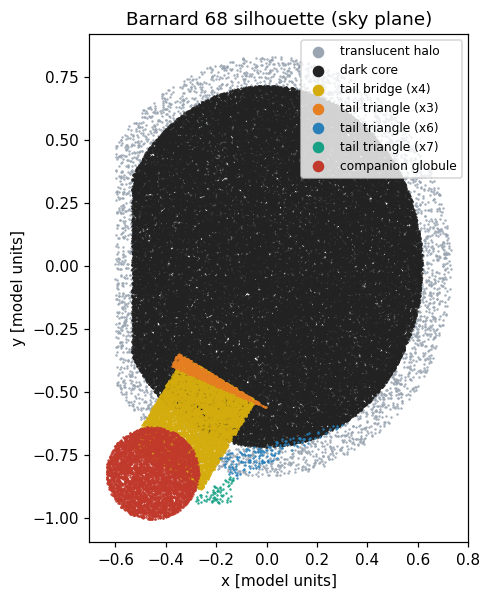

In [19]:
fig, ax = plt.subplots(figsize=(6.2, 6))
cols = {1: "#222222", 5: "#9aa5b1", 2: "#c0392b", 3: "#e67e22", 4: "#d4ac0d", 6: "#16a085", 7: "#2980b9"}
for k in [5, 1, 4, 3, 6, 7, 2]:
    m = comp_flat == k
    ax.scatter(xyz_flat[m, 0], xyz_flat[m, 1], s=0.3, c=cols[k], label=COMP_NAMES[k], rasterized=True)
ax.set_aspect("equal"); ax.set_xlabel("x [model units]"); ax.set_ylabel("y [model units]")
ax.set_title("Barnard 68 silhouette (sky plane)")
ax.legend(markerscale=12, fontsize=8, loc="upper right")
plt.show()

The cloud has 107 288 points: 81 538 in the dark core, 11 037 in the halo, 5 304 in the companion and 9 409 in the four tail pieces.

### 2.2 From silhouette to a 3-D globule

The silhouette is a thin slab ($|z| \le 0.025$ model units), too thin for line-of-sight kinematics, so each component gets a depth:

* The core and halo ellipses become ellipsoids with depth semi-axis $c = \text{depth\_ratio}\cdot b$. A point at $(x, y)$ is kept with probability $\sqrt{1-\rho^2}$, where $\rho^2 = x^2/b^2 + y^2/a^2$, and gets $z$ uniformly in $[-c\sqrt{1-\rho^2},\ c\sqrt{1-\rho^2}]$. This gives a uniform volume density and a column that falls off towards the rim. Where the core and halo overlap, their densities add.
* The companion becomes a sphere, built in the same way.
* The tail pieces become a slab of half-thickness `tail_h`.

A uniform ellipsoid still has a flat-topped column profile, while B68 is close to a Bonnor-Ebert sphere, so the radial structure is remapped by enclosed mass. Each particle has an ellipsoidal radius $\rho_3 = \sqrt{x^2/b^2 + y^2/a^2 + z^2/c^2}$ and an enclosed-mass fraction $q$ given by its rank in $\rho_3$. It is moved along its own ray to $\rho_3' = \xi(q)/\xi_{\max}$, where $\xi(q)$ inverts the Bonnor-Ebert mass profile. The profile follows from the isothermal Lane-Emden equation

$$
\frac{1}{\xi^2}\frac{d}{d\xi}\!\left(\xi^2\frac{d\psi}{d\xi}\right) = e^{-\psi},\qquad \psi(0) = \psi'(0) = 0, \tag{1}
$$
$$
\frac{M(<\xi)}{M(<\xi_{\max})} = \frac{\xi^2\psi'(\xi)}{\xi_{\max}^2\,\psi'(\xi_{\max})}, \qquad \frac{\rho}{\rho_c} = e^{-\psi}. \tag{2}
$$

The outline, including the flat cut edge, does not change. The companion uses a sub-critical $\xi_{\max} = 4$.

The mean halo radius $\sqrt{a_5 b_5}/\mu$ is scaled to $R_{\rm B68} = 12\,500\ \mathrm{AU} = 0.0606$ pc, and each particle gets the mass $M_{\rm B68}/N$.

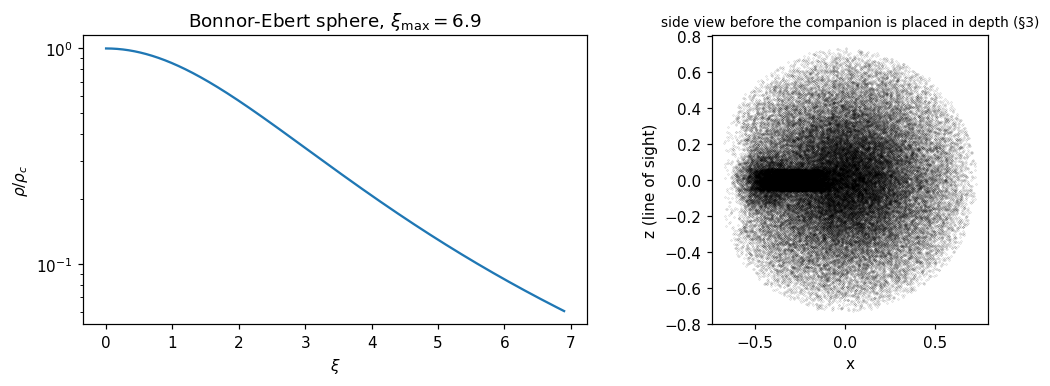

1 model unit = 0.0775 pc,  N = 75,676,  particle mass = 2.77e-05 Msun
mass fractions: core+halo 0.829, companion 0.046, tail 0.124


In [4]:
R_B68_PC, M_B68, DIST_PC = 0.0606, 2.1, 125.0


def inflate_to_3d(xyz, comp, p=B68_SHAPE, depth_ratio=1.0, tail_h=0.06, seed=1):
    rng = np.random.default_rng(seed)
    X, keep = xyz.copy(), np.ones(len(xyz), bool)
    miu = p["miu"]
    shells = {1: (p["a_ellips1"] / miu, p["b_ellips1"] / miu, 0.0, 0.0),
              5: (p["a_ellips5"] / miu, p["b_ellips5"] / miu, 0.0, 0.0),
              2: (p["Radius"] / miu, p["Radius"] / miu, p["X2"] / miu, p["Y2"] / miu)}
    for k, (a, b, x0, y0) in shells.items():
        m = np.where(comp == k)[0]
        rho2 = ((X[m, 0] - x0) / b) ** 2 + ((X[m, 1] - y0) / a) ** 2
        f = np.sqrt(np.clip(1 - rho2, 0, 1))
        keep[m] = rng.random(len(m)) < f                     # thin by column length
        X[m, 2] = rng.uniform(-1, 1, len(m)) * depth_ratio * b * f
    t = np.isin(comp, [3, 4, 6, 7])
    X[t, 2] = rng.uniform(-tail_h, tail_h, t.sum())
    return X[keep], comp[keep]


from scipy.integrate import solve_ivp


def be_mass_profile(xi_max, n=4000):
    # isothermal Lane-Emden: returns xi grid, enclosed-mass fraction, rho/rho_c
    rhs = lambda xi, y: [y[1], np.exp(-y[0]) - 2 * y[1] / xi]
    xi0 = 1e-4
    sol = solve_ivp(rhs, [xi0, xi_max], [xi0**2 / 6, xi0 / 3], dense_output=True, rtol=1e-10, atol=1e-12)
    xi = np.linspace(xi0, xi_max, n)
    psi, dpsi = sol.sol(xi)
    m = xi**2 * dpsi
    return xi, m / m[-1], np.exp(-psi)


def be_remap(X, sel, centre, axes, xi_max):
    # move particles in `sel` along their ellipsoidal rays so that M(<rho3) follows a BE sphere
    rel = (X[sel] - centre) / axes
    rho3 = np.linalg.norm(rel, axis=1)
    q = (np.argsort(np.argsort(rho3)) + 0.5) / sel.sum()
    xi, mfrac, _ = be_mass_profile(xi_max)
    rho_new = np.interp(q, mfrac, xi) / xi_max
    X = X.copy()
    X[sel] = centre + rel * (rho_new / np.maximum(rho3, 1e-12))[:, None] * axes
    return X


X3d, comp = inflate_to_3d(xyz_flat, comp_flat)
miu = B68_SHAPE["miu"]
b5, a5 = B68_SHAPE["b_ellips5"] / miu, B68_SHAPE["a_ellips5"] / miu
X3d = be_remap(X3d, np.isin(comp, [1, 5]), np.zeros(3), np.r_[b5, a5, b5], xi_max=6.9)
Rc_ = B68_SHAPE["Radius"] / miu
X3d = be_remap(X3d, comp == 2, np.r_[B68_SHAPE["X2"] / miu, B68_SHAPE["Y2"] / miu, 0.0],
               np.r_[Rc_, Rc_, Rc_], xi_max=4.0)

xi, mf, dens = be_mass_profile(6.9)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4), constrained_layout=True)
ax[0].semilogy(xi, dens); ax[0].set_xlabel(r"$\xi$"); ax[0].set_ylabel(r"$\rho/\rho_c$")
ax[0].set_title(r"Bonnor-Ebert sphere, $\xi_{\max}=6.9$")
ax[1].scatter(X3d[:, 0], X3d[:, 2], s=0.05, c="k", alpha=0.3, rasterized=True); ax[1].set_aspect("equal")
ax[1].set_xlabel("x"); ax[1].set_ylabel("z (line of sight)"); ax[1].set_title("side view before the companion is placed in depth (§3)", fontsize=9)
plt.show()

L_UNIT = R_B68_PC / (np.sqrt(B68_SHAPE["a_ellips5"] * B68_SHAPE["b_ellips5"]) / B68_SHAPE["miu"])
X0 = X3d * L_UNIT                                            # pc
NPART = len(X0)
M_P = M_B68 / NPART

grp_core = np.isin(comp, [1, 5]); grp_comp = comp == 2; grp_tail = np.isin(comp, [3, 4, 6, 7])
print(f"1 model unit = {L_UNIT:.4f} pc,  N = {NPART:,},  particle mass = {M_P:.2e} Msun")
print(f"mass fractions: core+halo {grp_core.mean():.3f}, companion {grp_comp.mean():.3f}, tail {grp_tail.mean():.3f}")

One model unit is 0.0775 pc. After thinning, $N = 75\,676$ particles remain, each of mass $2.77\times10^{-5}\,M_\odot$. The core and halo hold 82.9% of the mass, the companion 4.6% and the tail 12.4%. The companion therefore has about $0.1\,M_\odot$, half the mass used by Burkert & Alves (2009). Since its velocity is prescribed, this only affects the maps and $M(<r)$ in the infall term.

The density in the left panel drops by a factor of 16.6 from centre to edge, compared with 14.0 for a critical Bonnor-Ebert sphere.

## 3. The prescribed velocity field

Velocities are measured in the rest frame of the core (centroid $\mathbf c_0$). The observer is at $+z$, so $v_{\rm LOS} = -v_z$ and negative values are blueshifted.

### 3.1 Approach geometry

The companion moves towards $\mathbf c_0$ along

$$
\hat{\mathbf n} = \big(\cos i\;\hat{\mathbf n}_{\rm sky},\ \sin i\big), \tag{3}
$$

where $\hat{\mathbf n}_{\rm sky}$ is the direction from the companion to the core in the sky plane and $i$ is the inclination of the approach out of the sky plane. The companion starts behind the core, at $z_0 = -d_{\rm sky}\tan i$, and approaches us at $V_{\rm imp}\sin i \approx 0.16\ \mathrm{km\,s^{-1}}$.

Burkert & Alves (2009) interpret the infall of about $0.12\ \mathrm{km\,s^{-1}}$ in the south-east of B68 as the line-of-sight part of the companion's motion. With their impact speed of $0.4\ \mathrm{km\,s^{-1}}$ this gives an inclination of about $17^\circ$, close to our $i = 25^\circ$. Whether the companion moves towards us or away is our choice.

### 3.2 Lagrangian weights

Each particle carries a weight $w \in [0, 1]$: $w = 0$ for the core and halo, $w = 1$ for the companion, and in the tail $w$ grows linearly with the projected distance from the core edge towards the companion. The weights do not change with time.

### 3.3 Total velocity

The velocity of particle $j$ is the sum of three terms:

$$
\mathbf v_j(t) = \underbrace{w_j\,V(t)\,\hat{\mathbf n}}_{\text{impact + tail}}
\;+\;\underbrace{(1-w_j)\,\boldsymbol\Omega\times(\mathbf x_j-\mathbf c_0)}_{\text{rotation}}
\;-\;\underbrace{A(t)\,S(r_j,t)\,\sqrt{\frac{2G\,M(<r_j)}{r_j}}\;\Big(1-e^{-r_j^2/r_s^2}\Big)\,\hat{\mathbf r}_j}_{\text{triggered infall}} \tag{4}
$$

Before impact the companion moves at $V(t) = V_{\rm imp}$. The impact happens at $t_{\rm imp} = (d_0 - R_{\rm c})/V_{\rm imp}$, when the centre of the companion crosses the dark-core boundary $R_{\rm c}$. After that the companion is braked, $V(t) = V_{\rm imp}\,e^{-(t-t_{\rm imp})/\tau_{\rm drag}}$. Tail particles have intermediate $w$ and move slower, so the tail is squeezed between the companion and the core.

The rotation term is a slow solid-body rotation $\boldsymbol\Omega$ about an axis in the sky plane. It gives a small velocity gradient across the cloud, like the gradients observed in B68 by Lada et al. (2003).

The collision removes pressure support. For $t > t_{\rm imp}$ the infall speed is a fraction $A(t) = A_\infty\big(1-e^{-(t-t_{\rm imp})/\tau_{\rm ramp}}\big)$ of the local escape speed, and $M(<r)$ is recomputed from the particles at every RK stage. As in the inside-out collapse of Shu (1977), only gas inside a front moving outwards at the sound speed falls in:

$$
S(r,t) = \tfrac12\Big[1-\tanh\frac{r-r_f(t)}{\Delta}\Big],\qquad r_f = c_s\,(t-t_{\rm imp}). \tag{5}
$$

The centre collapses first; the envelope stays in place until the front reaches it. The softening radius $r_s$ stands in for the protostar. $c_s = 0.24\ \mathrm{km\,s^{-1}}$ is the sound speed at 16 K, the temperature adopted by Alves et al. (2001). The 10.5 K measured by Lada et al. (2003) would give $0.19\ \mathrm{km\,s^{-1}}$ and a slower front.

In [5]:
KIN = dict(
    v_imp=0.37,        # km/s   companion approach speed (Burkert & Alves 2009)
    incl_deg=25.0,     # deg    inclination of the approach out of the sky plane
    tau_drag=0.03,     # Myr    braking time of the companion inside the core
    A_inf=0.5,         #        infall speed / escape speed once support is lost
    tau_ramp=0.03,     # Myr    how quickly support is lost after impact
    c_s=0.24,          # km/s   speed of the collapse front (sound speed at T = 16 K)
    front_width=0.006, # pc     softness of the front
    r_sink=0.003,      # pc     softening radius ("protostar")
    omega=0.6,         # km/s/pc  solid-body rotation rate
    rot_pa_deg=30.0,   # deg    position angle of the rotation axis in the sky plane
    sigma_line=0.08,   # km/s   line width for synthetic spectra (C18O-like: thermal + small turbulence)
    t_end=0.40, dt=0.001, snap_every=10,   # Myr
)

# --- geometry of the encounter -------------------------------------------------
c0 = X0[grp_core].mean(0)
cc = X0[grp_comp].mean(0)
d_sky_vec = (c0 - cc)[:2]
d_sky = np.linalg.norm(d_sky_vec)
n_sky = d_sky_vec / d_sky                       # companion -> core (sky plane)
inc = np.radians(KIN["incl_deg"])
n_hat = np.r_[n_sky * np.cos(inc), np.sin(inc)]

# projection of every particle on the core -> companion axis
s_proj = (X0[:, :2] - c0[:2]) @ (-n_sky)
R_c = np.percentile(s_proj[comp == 1], 99.5)    # dark-core edge along the axis
s_edge = np.percentile(s_proj[grp_core], 99.5)  # halo edge along the axis
w = np.zeros(NPART)
w[grp_comp] = 1.0
w[grp_tail] = np.clip((s_proj[grp_tail] - 0.6 * s_edge) / (d_sky - 0.6 * s_edge), 0, 1)

# put the companion (and, proportionally, the tail) behind the core
z_off = -d_sky * np.tan(inc)
X0[:, 2] += w * z_off

d0 = d_sky / np.cos(inc)                        # 3-D distance companion -> core centre
t_imp = (d0 - R_c) / (KIN["v_imp"] * KMS)

ax_rot = np.radians(KIN["rot_pa_deg"])
Omega_vec = KIN["omega"] * np.r_[np.cos(ax_rot), np.sin(ax_rot), 0.0]

print(f"sky separation {d_sky*1e3:.1f} mpc, 3-D {d0*1e3:.1f} mpc, dark-core radius along axis {R_c*1e3:.1f} mpc")
print(f"impact time t_imp = {t_imp*1e3:.0f} kyr   (projected approach speed {KIN['v_imp']*np.cos(inc):.3f} km/s)")
v_esc = np.sqrt(2 * G * M_B68 / R_B68_PC)
print(f"escape speed at R_B68: {v_esc:.2f} km/s,  free-fall time of mean density: "
      f"{np.pi/2*np.sqrt(R_B68_PC**3/(2*G*M_B68))/KMS:.2f} Myr")

sky separation 73.0 mpc, 3-D 80.6 mpc, dark-core radius along axis 54.3 mpc
impact time t_imp = 69 kyr   (projected approach speed 0.335 km/s)
escape speed at R_B68: 0.55 km/s,  free-fall time of mean density: 0.17 Myr


The companion starts 73 mpc from the core centre in projection and 80.6 mpc in 3-D. It reaches the dark-core edge (54.3 mpc along the axis) at $t_{\rm imp} \approx 69$ kyr, moving across the sky at $V_{\rm imp}\cos i = 0.335\ \mathrm{km\,s^{-1}}$; Section 6.4 recovers this speed from the images. The escape speed at $R_{\rm B68}$ is $0.55\ \mathrm{km\,s^{-1}}$ and the free-fall time of the mean density is 0.17 Myr, as in Burkert & Alves (2009).

In [6]:
def companion_speed(t):
    return KIN["v_imp"] if t < t_imp else KIN["v_imp"] * np.exp(-(t - t_imp) / KIN["tau_drag"])


def infall_amp(t):
    return 0.0 if t < t_imp else KIN["A_inf"] * (1 - np.exp(-(t - t_imp) / KIN["tau_ramp"]))


def velocity(t, X):
    # velocity field [km/s] at time t [Myr] for positions X [pc]
    rv = X - c0
    v = np.outer(w * companion_speed(t), n_hat)                 # impact + tail compression
    v += (1 - w)[:, None] * np.cross(Omega_vec, rv)             # rotation of the core
    A = infall_amp(t)
    if A > 0:                                                   # triggered infall
        r = np.linalg.norm(rv, axis=1)
        order = np.argsort(r)
        Menc = np.empty(NPART); Menc[order] = M_P * np.arange(1, NPART + 1)
        r_safe = np.maximum(r, 1e-6)
        r_f = KIN["c_s"] * KMS * (t - t_imp)
        S = 0.5 * (1 - np.tanh((r_safe - r_f) / KIN["front_width"]))
        vin = A * S * np.sqrt(2 * G * Menc / r_safe) * (1 - np.exp(-(r_safe / KIN["r_sink"]) ** 2))
        v -= (vin / r_safe)[:, None] * rv
    return v

## 4. Numerical integration

The particle paths solve $\dot{\mathbf x} = \mathbf v(t, \mathbf x)$, with $\mathbf v$ converted to pc/Myr. They are integrated with the classical fourth-order Runge-Kutta method (Press et al. 2007) with step $h$:

$$
\begin{aligned}
\mathbf k_1 &= \mathbf v(t_n,\ \mathbf x_n), & \mathbf k_2 &= \mathbf v\!\left(t_n + \tfrac h2,\ \mathbf x_n + \tfrac h2\,\mathbf k_1\right),\\
\mathbf k_3 &= \mathbf v\!\left(t_n + \tfrac h2,\ \mathbf x_n + \tfrac h2\,\mathbf k_2\right), & \mathbf k_4 &= \mathbf v\!\left(t_n + h,\ \mathbf x_n + h\,\mathbf k_3\right),\\
\mathbf x_{n+1} &= \mathbf x_n + \tfrac h6\left(\mathbf k_1 + 2\mathbf k_2 + 2\mathbf k_3 + \mathbf k_4\right).
\end{aligned}
\tag{6}
$$

We use $h = 1$ kyr up to 0.4 Myr and save every 10th step as `float32`, which gives 41 snapshots.

In [7]:
import time

def integrate(X_init, t_end=KIN["t_end"], dt=KIN["dt"], snap_every=KIN["snap_every"]):
    X = X_init.copy(); t = 0.0
    nsteps = int(round(t_end / dt))
    times, XS, VS = [], [], []
    for step in range(nsteps + 1):
        if step % snap_every == 0:
            times.append(t); XS.append(X.astype(np.float32)); VS.append(velocity(t, X).astype(np.float32))
        if step == nsteps:
            break
        k1 = velocity(t, X)
        k2 = velocity(t + dt / 2, X + 0.5 * dt * KMS * k1)
        k3 = velocity(t + dt / 2, X + 0.5 * dt * KMS * k2)
        k4 = velocity(t + dt, X + dt * KMS * k3)
        X = X + dt * KMS * (k1 + 2 * k2 + 2 * k3 + k4) / 6
        t += dt
    return np.array(times), np.stack(XS), np.stack(VS)

t0 = time.time()
T, XS, VS = integrate(X0)
print(f"{len(T)} snapshots, t = 0 ... {T[-1]:.2f} Myr, {time.time()-t0:.1f} s")

41 snapshots, t = 0 ... 0.40 Myr, 64.7 s


## 5. Synthetic observations

### 5.1 Extinction maps

The surface density $\Sigma$ is converted to $N(\mathrm H_2)$ with a mean mass of $2.8\,m_{\rm H}$ per H$_2$ molecule, and then to visual extinction with $N(\mathrm H_2) = 9.4\times10^{20}\,A_V\ \mathrm{cm^{-2}}$ (Bohlin et al. 1978, $R_V = 3.1$). The maps are smoothed with a Gaussian beam of 0.0015 pc, about $2.5''$ at 125 pc.

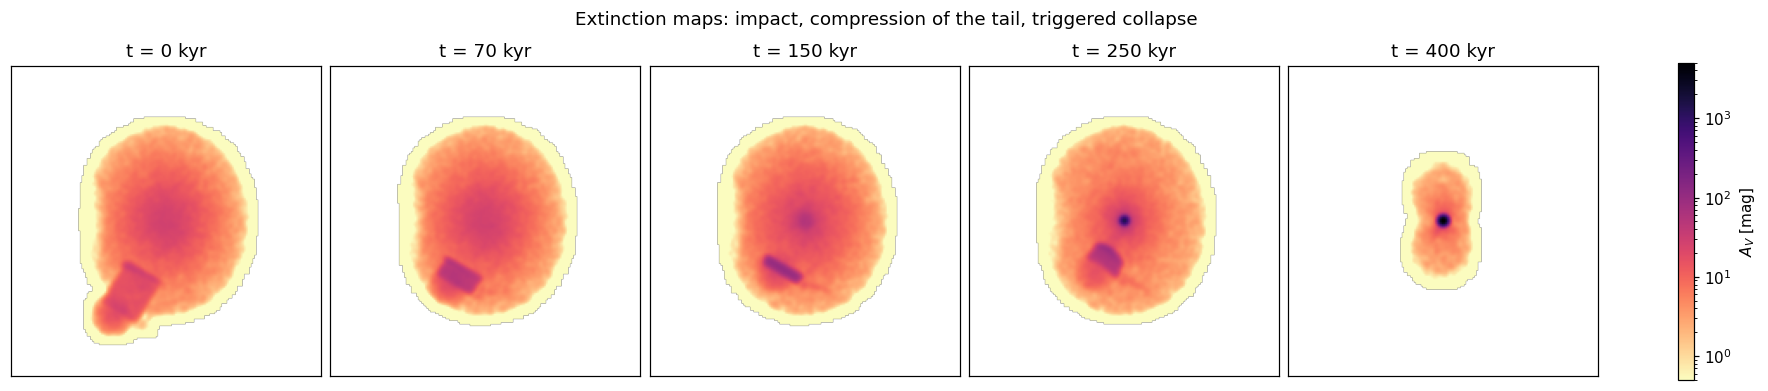

In [8]:
EXT, NPIX, BEAM = 0.105, 180, 0.0015
PIX = 2 * EXT / NPIX
edges = [np.linspace(c0[0] - EXT, c0[0] + EXT, NPIX + 1), np.linspace(c0[1] - EXT, c0[1] + EXT, NPIX + 1)]
xg = 0.5 * (edges[0][1:] + edges[0][:-1]); yg = 0.5 * (edges[1][1:] + edges[1][:-1])
EXTENT = [edges[0][0], edges[0][-1], edges[1][0], edges[1][-1]]


def hist_map(X, weights=None):
    H, _, _ = np.histogram2d(X[:, 0], X[:, 1], bins=edges, weights=weights)
    return ndimage.gaussian_filter(H.T, BEAM / PIX)


def av_map(X):
    return hist_map(X) * M_P / PIX**2 * SIGMA_TO_AV


def moment_maps(X, V, av_min=1.0):
    vlos = -V[:, 2].astype(float)
    h0 = hist_map(X); h1 = hist_map(X, vlos); h2 = hist_map(X, vlos**2)
    with np.errstate(invalid="ignore", divide="ignore"):
        m1 = h1 / h0
        m2 = np.sqrt(np.clip(h2 / h0 - m1**2, 0, None) + KIN["sigma_line"]**2)
    mask = av_map(X) < av_min
    return np.ma.array(m1, mask=mask), np.ma.array(m2, mask=mask)


AV = np.array([av_map(X) for X in XS])
i_imp = np.searchsorted(T, t_imp)
show_i = [0, i_imp, i_imp + 8, i_imp + 18, len(T) - 1]

fig, axs = plt.subplots(1, len(show_i), figsize=(16, 3.6), constrained_layout=True)
for ax, i in zip(axs, show_i):
    im = ax.imshow(AV[i], extent=EXTENT, norm=LogNorm(0.5, AV.max()), cmap="magma_r")
    ax.set_title(f"t = {T[i]*1e3:.0f} kyr"); ax.set_xticks([]); ax.set_yticks([])
fig.colorbar(im, ax=axs, label=r"$A_V$ [mag]", shrink=0.9)
fig.suptitle("Extinction maps: impact, compression of the tail, triggered collapse")
plt.show()

At $t = 70$ kyr the companion has reached the edge of the core and the tail has been pressed into a short bar. By 150 kyr a dense peak has appeared in the centre. At 250 kyr it exceeds $10^3$ mag, while the outline has hardly changed because the collapse front has not yet reached the envelope. By 400 kyr the envelope has fallen in as well, leaving a compact, elongated cloud around the central condensation.

### 5.2 Optical view

In optical images B68 is a dark hole in a dense star field. To mimic this, a random field of background stars is dimmed by the extinction map in the R band, with $A_R \approx 0.75\,A_V$ (Cardelli et al. 1989).

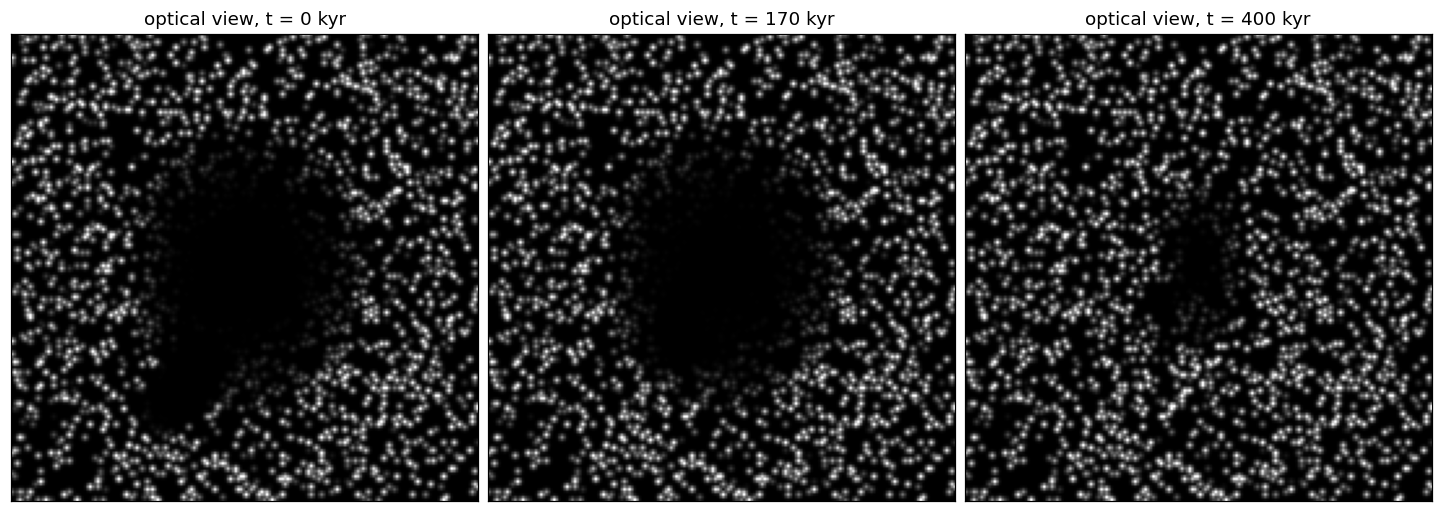

In [9]:
# background star field dimmed by the cloud
rng = np.random.default_rng(7)
nstar = 2200
sx, sy = rng.uniform(EXTENT[0], EXTENT[1], nstar), rng.uniform(EXTENT[2], EXTENT[3], nstar)
mag = rng.exponential(1.2, nstar)                       # many faint stars, a few bright ones
ix = np.clip(((sx - EXTENT[0]) / PIX).astype(int), 0, NPIX - 1)
iy = np.clip(((sy - EXTENT[2]) / PIX).astype(int), 0, NPIX - 1)


def optical_view(av, band_ratio=0.75):                    # R band: A_R ~ 0.75 A_V
    img = np.zeros((NPIX, NPIX))
    np.add.at(img, (iy, ix), 10 ** (-0.4 * (mag + band_ratio * av[iy, ix])))
    return ndimage.gaussian_filter(img, 0.6)


vmax_opt = np.percentile(optical_view(np.zeros_like(AV[0])), 99.7) ** 0.5
fig, axs = plt.subplots(1, 3, figsize=(13, 4.6), constrained_layout=True)
for ax, i in zip(axs, [0, i_imp + 10, len(T) - 1]):
    ax.imshow(np.sqrt(optical_view(AV[i])), extent=EXTENT, cmap="gray", vmax=vmax_opt)
    ax.set_title(f"optical view, t = {T[i]*1e3:.0f} kyr"); ax.set_xticks([]); ax.set_yticks([])
plt.show()

For the first 170 kyr the globule stays an opaque patch with a soft edge. By 400 kyr most of the envelope has fallen into the centre, the outer parts have become transparent and only a small dark spot is left.

### 5.3 Moment maps

For optically thin emission the first two moments of the line-of-sight velocity are

$$
M_1 = \langle v_{\rm LOS}\rangle, \qquad M_2 = \sqrt{\langle v_{\rm LOS}^2\rangle - M_1^2 + \sigma_{\rm line}^2}, \tag{7}
$$

where the averages are weighted by column density. Pixels with $A_V < 1$ mag are masked.

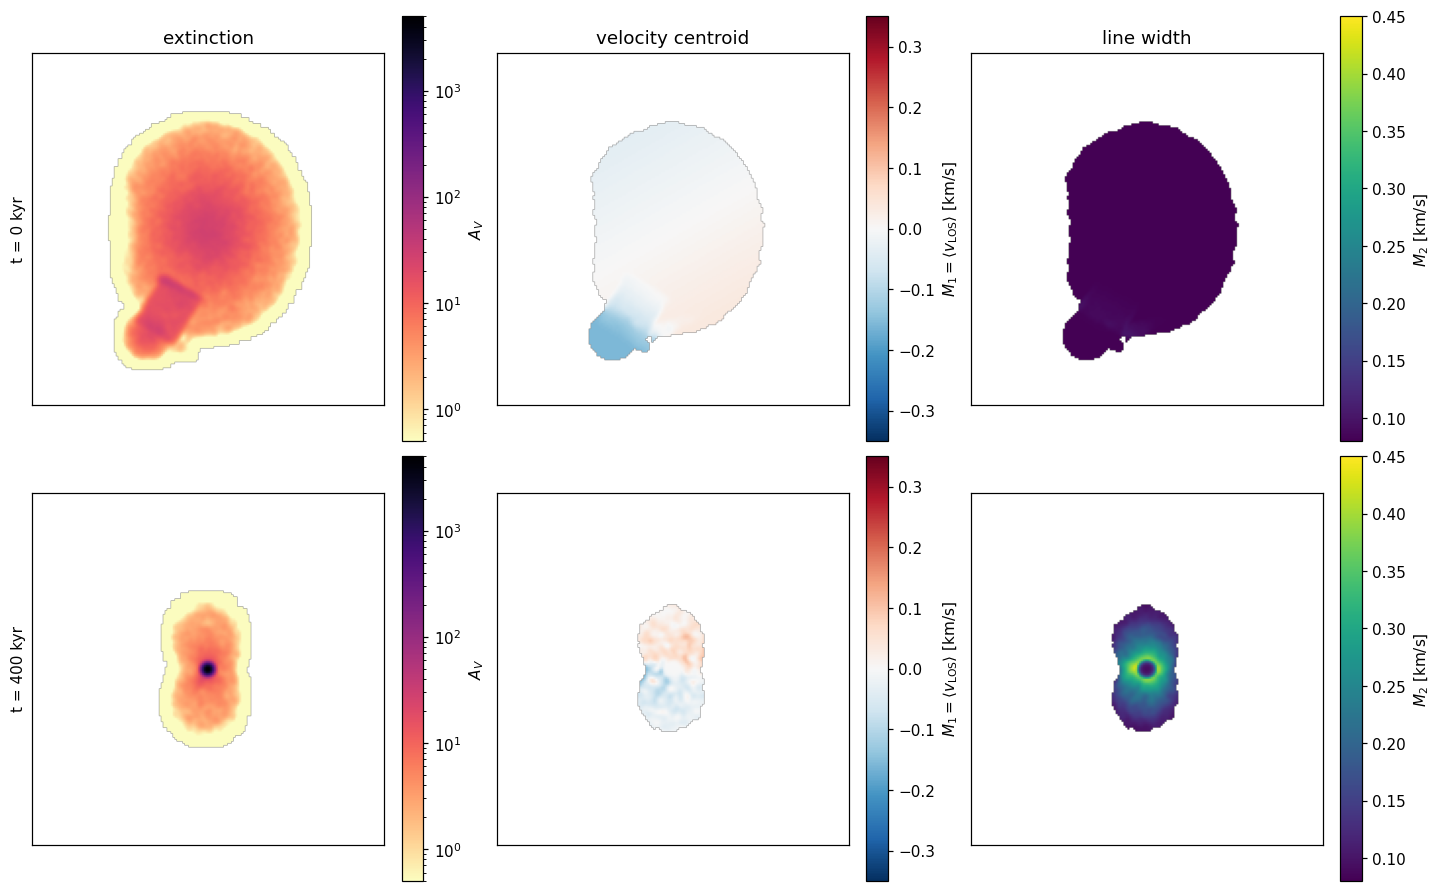

In [10]:
fig, axs = plt.subplots(2, 3, figsize=(13, 8), constrained_layout=True)
for row, i in enumerate([0, len(T) - 1]):
    m1, m2 = moment_maps(XS[i], VS[i])
    a = axs[row, 0].imshow(AV[i], extent=EXTENT, norm=LogNorm(0.5, AV.max()), cmap="magma_r")
    fig.colorbar(a, ax=axs[row, 0], label=r"$A_V$")
    b = axs[row, 1].imshow(m1, extent=EXTENT, cmap="RdBu_r", vmin=-0.35, vmax=0.35)
    fig.colorbar(b, ax=axs[row, 1], label=r"$M_1=\langle v_{\rm LOS}\rangle$ [km/s]")
    c = axs[row, 2].imshow(m2, extent=EXTENT, cmap="viridis", vmin=0.08, vmax=0.45)
    fig.colorbar(c, ax=axs[row, 2], label=r"$M_2$ [km/s]")
    for ax in axs[row]:
        ax.set_xticks([]); ax.set_yticks([])
    axs[row, 0].set_ylabel(f"t = {T[i]*1e3:.0f} kyr")
axs[0, 0].set_title("extinction"); axs[0, 1].set_title("velocity centroid"); axs[0, 2].set_title("line width")
plt.show()

In the first $M_1$ map the companion stands out at about $-0.16\ \mathrm{km\,s^{-1}} = -V_{\rm imp}\sin i$, while the core shows only the weak rotation gradient. At 400 kyr the line width $M_2$ reaches about $0.4\ \mathrm{km\,s^{-1}}$ around the centre.

The infall does not show up in $M_1$: gas in front of the centre and behind it moves in opposite directions along the line of sight, so the mean cancels. It appears instead as a broader line in $M_2$ and as a double-peaked profile in the position-velocity diagram and spectra below. Optically thick lines would show a blue asymmetry, which an optically thin model cannot reproduce.

### 5.4 Position-velocity diagram and spectra

The position-velocity (PV) diagram is cut along the impact axis through a slit 0.016 pc wide and shown with a logarithmic stretch. The spectra are averaged over the annulus $0.004 < r < 0.012$ pc, so that the unresolved central condensation does not dominate the line.

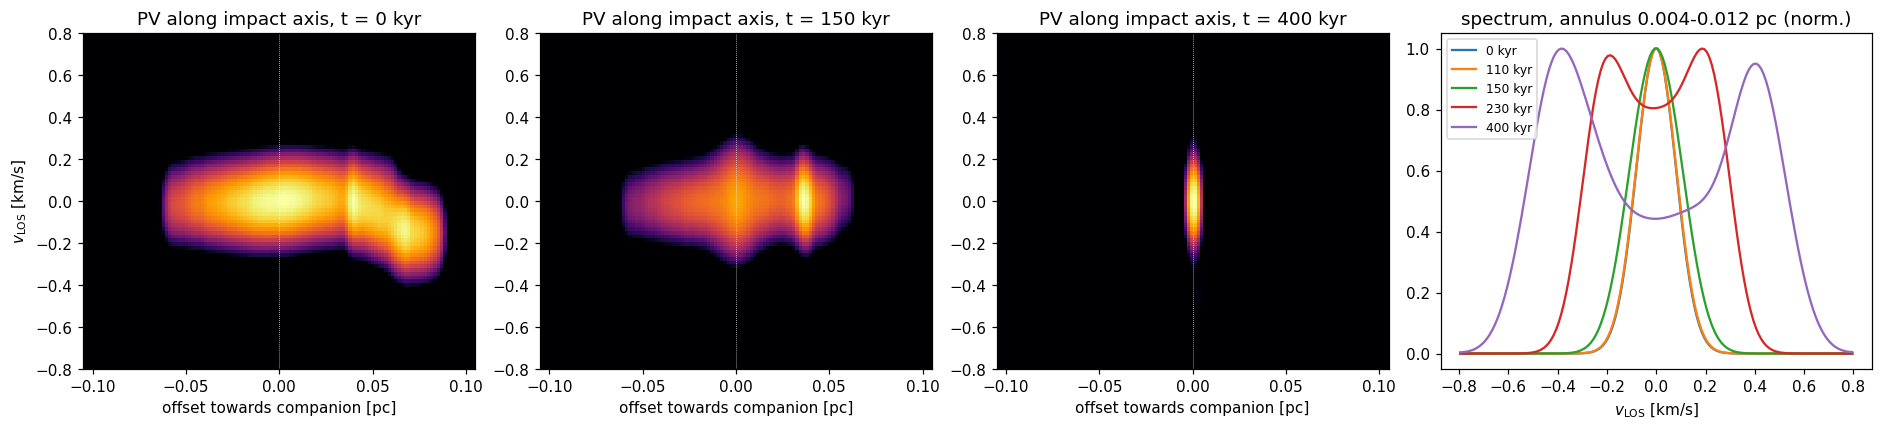

In [11]:
def pv_diagram(X, V, slit=0.008, vmax=0.8, nv=90, ns=120):
    rel = X[:, :2] - c0[:2]
    s = rel @ (-n_sky)                                   # offset along the core->companion axis
    q = rel @ np.r_[-n_sky[1], n_sky[0]]                 # perpendicular offset
    m = np.abs(q) < slit
    vlos = -V[m, 2]
    H, se, ve = np.histogram2d(s[m], vlos, bins=[ns, nv], range=[[-EXT, EXT], [-vmax, vmax]])
    dv = ve[1] - ve[0]
    H = ndimage.gaussian_filter(H.T, [KIN["sigma_line"] / dv, BEAM / (se[1] - se[0])])
    return H, [se[0], se[-1], ve[0], ve[-1]]


def ring_spectrum(X, V, r_in=0.004, r_out=0.012, vmax=0.8, nv=160):
    rr = np.hypot(*(X[:, :2] - c0[:2]).T)
    m = (rr > r_in) & (rr < r_out)
    H, ve = np.histogram(-V[m, 2], bins=nv, range=(-vmax, vmax))
    vc = 0.5 * (ve[1:] + ve[:-1])
    return vc, ndimage.gaussian_filter1d(H.astype(float), KIN["sigma_line"] / (ve[1] - ve[0]))


fig, axs = plt.subplots(1, 4, figsize=(17, 3.8), constrained_layout=True,
                        gridspec_kw=dict(width_ratios=[1, 1, 1, 1.1]))
for ax, i in zip(axs[:3], [0, i_imp + 8, len(T) - 1]):
    H, ext = pv_diagram(XS[i], VS[i])
    ax.imshow(H + 1e-9, extent=ext, aspect="auto", cmap="inferno", norm=LogNorm(H.max() * 3e-3, H.max()))
    ax.axvline(0, c="w", lw=0.5, ls=":")
    ax.set_title(f"PV along impact axis, t = {T[i]*1e3:.0f} kyr")
    ax.set_xlabel("offset towards companion [pc]")
axs[0].set_ylabel(r"$v_{\rm LOS}$ [km/s]")
for i in [0, i_imp + 4, i_imp + 8, i_imp + 16, len(T) - 1]:
    vc, sp = ring_spectrum(XS[i], VS[i])
    axs[3].plot(vc, sp / sp.max(), label=f"{T[i]*1e3:.0f} kyr")
axs[3].set_xlabel(r"$v_{\rm LOS}$ [km/s]"); axs[3].set_title("spectrum, annulus 0.004-0.012 pc (norm.)")
axs[3].legend(fontsize=8)
plt.show()

In the first PV diagram the companion is a separate blueshifted clump 0.04 to 0.09 pc from the centre. At 150 kyr it has been braked to the core velocity and sits at about 0.035 pc. By 400 kyr all the emission comes from the centre. The spectra stay single-peaked up to 150 kyr. At 230 kyr the line splits into two peaks at about $\pm0.2\ \mathrm{km\,s^{-1}}$, and by 400 kyr the peaks are at about $\pm0.4\ \mathrm{km\,s^{-1}}$ as the infall speeds up.

### 5.5 Animation

The animation shows the extinction map and the velocity centroid for all 41 snapshots and is saved as `b68_evolution.gif`.

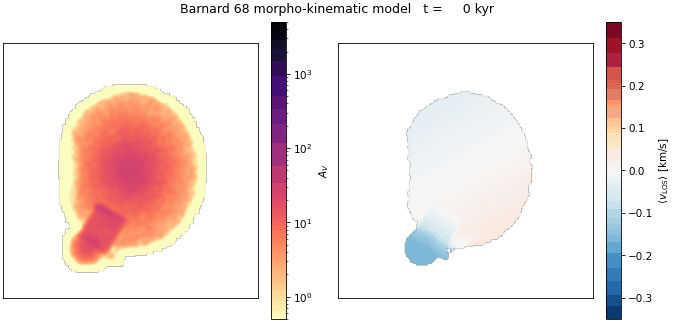

In [12]:
fig, axs = plt.subplots(1, 2, figsize=(9, 4.3), constrained_layout=True)
im0 = axs[0].imshow(AV[0], extent=EXTENT, norm=LogNorm(0.5, AV.max()), cmap="magma_r")
m1, _ = moment_maps(XS[0], VS[0])
im1 = axs[1].imshow(m1, extent=EXTENT, cmap="RdBu_r", vmin=-0.35, vmax=0.35)
fig.colorbar(im0, ax=axs[0], label=r"$A_V$"); fig.colorbar(im1, ax=axs[1], label=r"$\langle v_{\rm LOS}\rangle$ [km/s]")
for ax in axs:
    ax.set_xticks([]); ax.set_yticks([])
title = fig.suptitle("")

def frame(i):
    im0.set_data(AV[i])
    im1.set_data(moment_maps(XS[i], VS[i])[0])
    title.set_text(f"Barnard 68 morpho-kinematic model   t = {T[i]*1e3:5.0f} kyr"
                   + ("   (after impact)" if T[i] >= t_imp else ""))
    return im0, im1, title

anim = animation.FuncAnimation(fig, frame, frames=len(T), blit=False)
anim.save("b68_evolution.gif", writer=animation.PillowWriter(fps=6), dpi=75)
plt.close(fig)
display(Image(filename="b68_evolution.gif"))

## 6. Spline approximations

Particle maps are noisy, and most of the quantities below need derivatives, so the data are fitted with smoothing splines. They are used in five ways.

### 6.1 Closed parametric spline of the cloud boundary

The $A_V$ iso-contour $\{(x_k, y_k)\}$ is fitted with a periodic cubic B-spline $\mathbf s(u) = (x(u), y(u))$, $u \in [0, 1)$, using `splprep(per=1)` (Dierckx 1993). The smoothing allows a typical residual of about 1.5 pixels, enough to suppress shot noise along the faint rim. The spline gives the curvature, area, perimeter and circularity:

$$
\kappa(u) = \frac{x'y'' - y'x''}{\left(x'^2 + y'^2\right)^{3/2}},\qquad
A = \tfrac12\oint (x\,y' - y\,x')\,du,\qquad
P = \oint\sqrt{x'^2 + y'^2}\,du,\qquad
\mathcal C = \frac{4\pi A}{P^2}. \tag{8}
$$

$\mathcal C = 1$ for a circle and is smaller for any other shape.

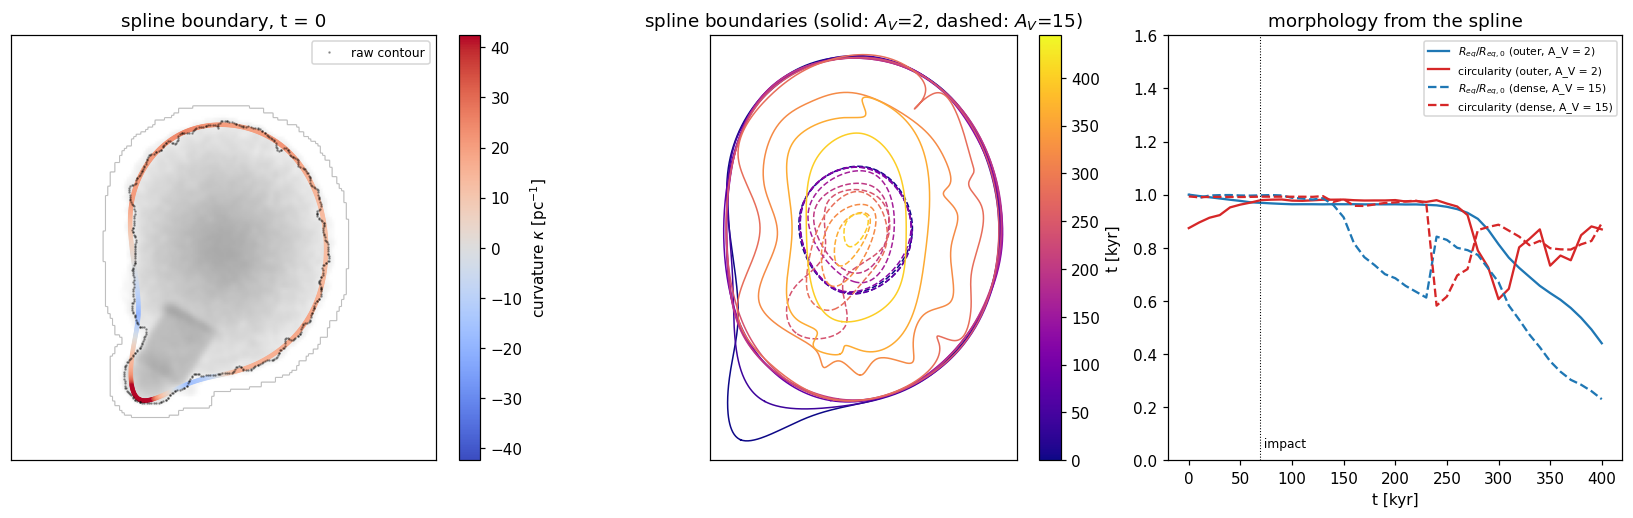

In [13]:
def longest_contour(av, level):
    lines = contourpy.contour_generator(xg, yg, av).lines(level)
    return max(lines, key=len) if lines else None


def closed_spline(pts, n_eval=600, resid=1.5 * PIX):
    keep = np.r_[True, np.any(np.diff(pts, axis=0) != 0, axis=1)]   # drop repeated points
    pts = pts[keep]
    if not np.allclose(pts[0], pts[-1]):
        pts = np.vstack([pts, pts[:1]])
    tck, _ = splprep([pts[:, 0], pts[:, 1]], s=len(pts) * resid**2, per=1)
    u = np.linspace(0, 1, n_eval)
    x, y = splev(u, tck); dx, dy = splev(u, tck, der=1); ddx, ddy = splev(u, tck, der=2)
    speed = np.hypot(dx, dy)
    kappa = (dx * ddy - dy * ddx) / speed**3
    A = 0.5 * abs(np.trapezoid(x * dy - y * dx, u))
    P = np.trapezoid(speed, u)
    return dict(x=x, y=y, kappa=kappa, area=A, perim=P, circ=4 * np.pi * A / P**2)


lev_dense = round(0.5 * AV[0].max())
LEVELS = {"outer, A_V = 2": 2.0, f"dense, A_V = {lev_dense}": float(lev_dense)}
NAN_B = dict(x=np.array([]), y=np.array([]), kappa=np.array([]), area=np.nan, perim=np.nan, circ=np.nan)


def boundary_spline(av, lev):
    c = longest_contour(av, lev)
    return NAN_B if c is None or len(c) < 12 else closed_spline(c)


boundary = {name: [boundary_spline(av, lev) for av in AV] for name, lev in LEVELS.items()}

fig, axs = plt.subplots(1, 3, figsize=(15, 4.6), constrained_layout=True)
# (a) curvature along the outer boundary at t=0
b0 = boundary["outer, A_V = 2"][0]
axs[0].imshow(AV[0], extent=EXTENT, norm=LogNorm(0.5, AV.max()), cmap="Greys")
sc = axs[0].scatter(b0["x"], b0["y"], c=b0["kappa"], s=4, cmap="coolwarm",
                    vmin=-np.percentile(abs(b0["kappa"]), 95), vmax=np.percentile(abs(b0["kappa"]), 95))
c_raw = longest_contour(AV[0], 2.0)
axs[0].plot(c_raw[:, 0], c_raw[:, 1], "k.", ms=1.2, alpha=0.4, label="raw contour")
fig.colorbar(sc, ax=axs[0], label=r"curvature $\kappa$ [pc$^{-1}$]"); axs[0].legend(fontsize=8)
axs[0].set_title("spline boundary, t = 0"); axs[0].set_xticks([]); axs[0].set_yticks([])
# (b) evolution of the boundaries
cm = plt.cm.plasma(np.linspace(0, 0.9, len(T)))
for i in range(0, len(T), 4):
    for name, ls in zip(LEVELS, ["-", "--"]):
        b = boundary[name][i]
        axs[1].plot(b["x"], b["y"], ls, c=cm[i], lw=1)
axs[1].set_aspect("equal"); axs[1].set_title(f"spline boundaries (solid: $A_V$=2, dashed: $A_V$={lev_dense})")
axs[1].set_xticks([]); axs[1].set_yticks([])
sm = plt.cm.ScalarMappable(cmap="plasma", norm=plt.Normalize(0, T[-1] * 1e3 / 0.9)); fig.colorbar(sm, ax=axs[1], label="t [kyr]")
# (c) morphology metrics
for name, ls in zip(LEVELS, ["-", "--"]):
    req = np.array([np.sqrt(b["area"] / np.pi) for b in boundary[name]]) * 1e3
    circ = np.array([b["circ"] for b in boundary[name]])
    axs[2].plot(T * 1e3, req / req[0], ls, c="C0", label=f"$R_{{eq}}/R_{{eq,0}}$ ({name})")
    axs[2].plot(T * 1e3, circ, ls, c="C3", label=f"circularity ({name})")
axs[2].axvline(t_imp * 1e3, c="k", lw=0.7, ls=":"); axs[2].text(t_imp * 1e3, 0.05, " impact", fontsize=8)
axs[2].set_xlabel("t [kyr]"); axs[2].legend(fontsize=7); axs[2].set_ylim(0, 1.6)
axs[2].set_title("morphology from the spline")
plt.show()

On the initial outline the curvature is largest at the tip of the companion ($\kappa \approx 40\ \mathrm{pc^{-1}}$) and negative at the neck between the companion and the core, the only concave part of the outline. Before impact the circularity of the outer boundary ($A_V = 2$) rises from 0.88 to about 0.97 as the companion merges into the outline. The equivalent radius of the dense contour ($A_V = 15$) starts to shrink at about 150 kyr. The outer boundary keeps its size until about 270 kyr and then shrinks to less than half of its initial radius by 400 kyr. The jumps in circularity between 230 and 300 kyr are probably switches between contour pieces, since only the longest contour at each level is fitted.

### 6.2 Smoothing spline of the column-density profile along the impact axis

$A_V$ is sampled along the core-to-companion axis, and $\ln A_V(s)$ is fitted with a quartic smoothing spline $f(s)$, so that $f'(s)$ is cubic and its roots can be found directly. The roots give the core peak, the "neck" between core and companion, and the companion peak. Following them in time gives the projected separation and the neck contrast $\Delta\ln A_V = f(s_{\rm comp}) - f(s_{\rm neck})$. The neck disappears once the companion merges with the core.

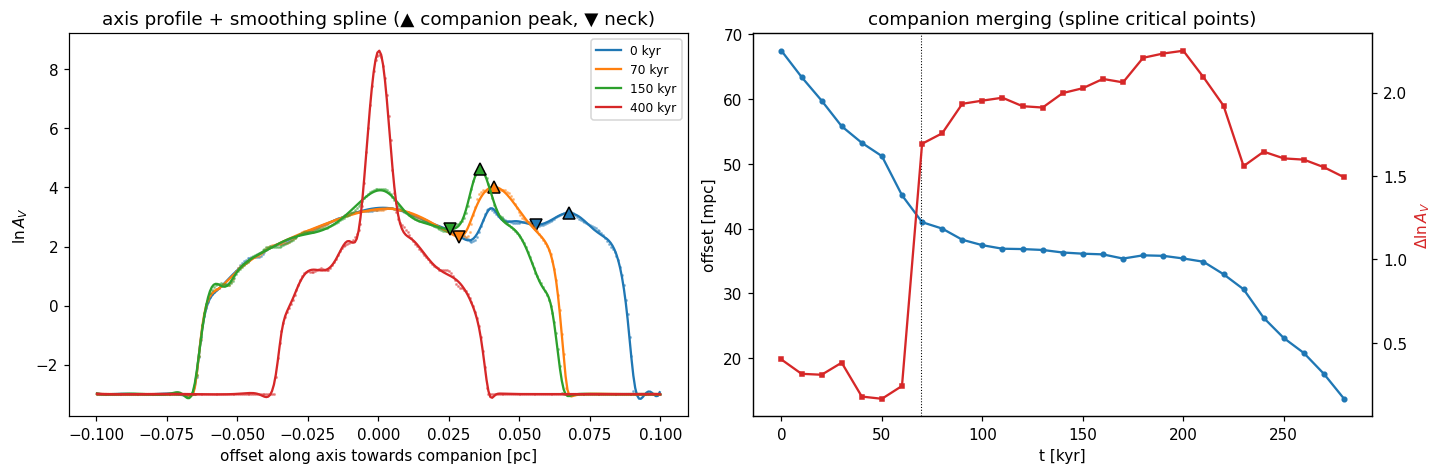

In [14]:
s_axis = np.linspace(-EXT * 0.95, EXT * 0.95, 300)
axis_xy = c0[:2][None, :] + s_axis[:, None] * (-n_sky)[None, :]
pix_coords = [(axis_xy[:, 1] - yg[0]) / PIX, (axis_xy[:, 0] - xg[0]) / PIX]   # (row, col)


def axis_profile_spline(av):
    prof = np.log(np.clip(ndimage.map_coordinates(av, pix_coords, order=1), 0.05, None))
    spl = UnivariateSpline(s_axis, prof, k=4, s=len(s_axis) * 0.004)   # k=4: cubic derivative for .roots()
    crit = spl.derivative().roots()
    curv = spl.derivative(2)(crit)
    return prof, spl, crit[curv < 0], crit[curv > 0]                # maxima, minima


def companion_peak(spl, maxima, minima, s_min=0.012, min_prom=0.15):
    # outermost maximum with prominence > min_prom above the nearest minimum on its core side
    for sm in np.sort(maxima[(maxima > s_min) & (spl(maxima) > np.log(2))])[::-1]:
        between = minima[(minima > 0) & (minima < sm)]
        if len(between) == 0:
            continue
        sn = between.max()
        prom = float(spl(sm) - spl(sn))
        if prom > min_prom:
            return sm, sn, prom
    return np.nan, np.nan, np.nan


sep, neck = [], []
fig, axs = plt.subplots(1, 2, figsize=(13, 4.2), constrained_layout=True)
for i in range(len(T)):
    prof, spl, mx, mn = axis_profile_spline(AV[i])
    sc_, sn_, prom = companion_peak(spl, mx, mn)
    sep.append(sc_); neck.append(prom)
    if i in [0, i_imp, i_imp + 8, len(T) - 1]:
        l, = axs[0].plot(s_axis, prof, ".", ms=2, alpha=0.4)
        axs[0].plot(s_axis, spl(s_axis), c=l.get_color(), label=f"{T[i]*1e3:.0f} kyr")
        if np.isfinite(sc_):
            axs[0].plot([sc_], [spl(sc_)], "^", c=l.get_color(), ms=8, mec="k")
            axs[0].plot([sn_], [spl(sn_)], "v", c=l.get_color(), ms=8, mec="k")
axs[0].set_xlabel("offset along axis towards companion [pc]"); axs[0].set_ylabel(r"$\ln A_V$")
axs[0].set_title("axis profile + smoothing spline (▲ companion peak, ▼ neck)"); axs[0].legend(fontsize=8)
sep, neck = np.array(sep), np.array(neck)
axs[1].plot(T * 1e3, sep * 1e3, "o-", ms=3, label="companion-peak offset [mpc]")
axb = axs[1].twinx(); axb.plot(T * 1e3, neck, "s-", ms=3, c="C3", label=r"neck contrast $\Delta\ln A_V$")
axs[1].axvline(t_imp * 1e3, c="k", lw=0.7, ls=":")
axs[1].set_xlabel("t [kyr]"); axs[1].set_ylabel("offset [mpc]"); axb.set_ylabel(r"$\Delta \ln A_V$", color="C3")
axs[1].set_title("companion merging (spline critical points)")
plt.show()

Before impact the companion peak moves in from 67 to 41 mpc at an almost constant rate. At impact the neck contrast jumps from about 0.3 to 1.7, as the compressed companion becomes much denser than the neck. From 100 to 200 kyr the braked companion stays at about 36 mpc. After about 210 kyr it moves in again, and after 280 kyr the spline no longer finds a separate peak: the companion has merged with the core.

### 6.3 Radial column-density profile and its logarithmic slope

The azimuthally averaged profile around the core peak, $\ln A_V(\ln r)$, is fitted with a smoothing spline. Its derivative gives the local power-law slope

$$
\gamma(r) = \frac{d\ln A_V}{d\ln r}. \tag{9}
$$

A globule before collapse has a flat inner part ($\gamma \approx 0$) and a steep edge. During collapse the inner profile should steepen towards $\Sigma \propto r^{-1}$, i.e. $\rho \propto r^{-2}$.

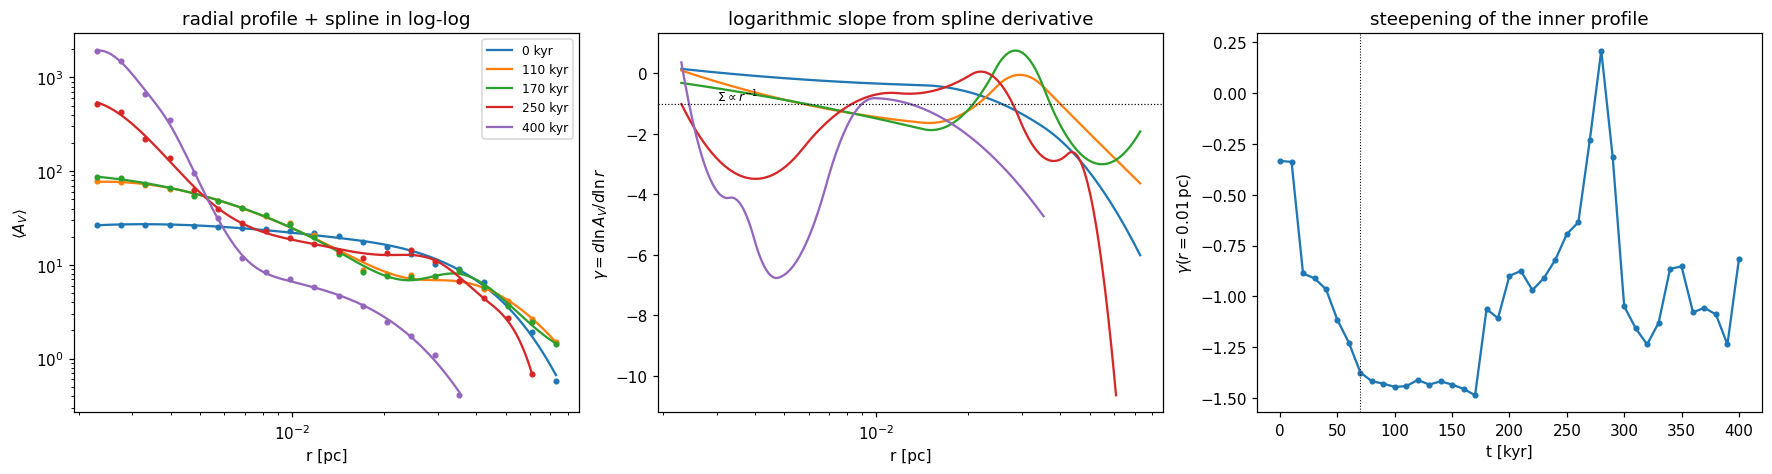

In [15]:
XX, YY = np.meshgrid(xg, yg)
rbins = np.geomspace(1.5 * PIX, 0.08, 22)


def radial_profile(av):
    pk = np.unravel_index(np.argmax(ndimage.gaussian_filter(av, 2)), av.shape)
    R = np.hypot(XX - xg[pk[1]], YY - yg[pk[0]])
    idx = np.digitize(R.ravel(), rbins)
    rc = np.sqrt(rbins[1:] * rbins[:-1])
    prof = np.array([av.ravel()[idx == k].mean() if np.any(idx == k) else np.nan for k in range(1, len(rbins))])
    ok = np.isfinite(prof) & (prof > 0.3)
    return rc[ok], prof[ok]


fig, axs = plt.subplots(1, 3, figsize=(16, 4.2), constrained_layout=True)
slopes_in = []
for i in range(len(T)):
    rc, prof = radial_profile(AV[i])
    lx, ly = np.log(rc), np.log(prof)
    spl = UnivariateSpline(lx, ly, k=3, s=len(lx) * 0.004)
    slopes_in.append(spl.derivative()(np.log(0.01)))           # slope at r = 0.01 pc
    if i in [0, i_imp + 4, i_imp + 10, i_imp + 18, len(T) - 1]:
        l, = axs[0].loglog(rc, prof, "o", ms=3)
        lxx = np.linspace(lx[0], lx[-1], 200)
        axs[0].loglog(np.exp(lxx), np.exp(spl(lxx)), c=l.get_color(), label=f"{T[i]*1e3:.0f} kyr")
        axs[1].semilogx(np.exp(lxx), spl.derivative()(lxx), c=l.get_color())
from matplotlib.ticker import NullFormatter
for ax in axs[:2]:
    ax.xaxis.set_minor_formatter(NullFormatter())
axs[0].set_xlabel("r [pc]"); axs[0].set_ylabel(r"$\langle A_V\rangle$"); axs[0].legend(fontsize=8)
axs[0].set_title("radial profile + spline in log-log")
axs[1].axhline(-1, c="k", ls=":", lw=0.8); axs[1].text(0.003, -0.93, r"$\Sigma\propto r^{-1}$", fontsize=8)
axs[1].set_xlabel("r [pc]"); axs[1].set_ylabel(r"$\gamma=d\ln A_V/d\ln r$"); axs[1].set_title("logarithmic slope from spline derivative")
axs[2].plot(T * 1e3, slopes_in, "o-", ms=3); axs[2].axvline(t_imp * 1e3, c="k", lw=0.7, ls=":")
axs[2].set_xlabel("t [kyr]"); axs[2].set_ylabel(r"$\gamma(r=0.01\,\mathrm{pc})$"); axs[2].set_title("steepening of the inner profile")
plt.show()

The initial profile is flat inside about 0.02 pc and steep at the edge, as expected for a Bonnor-Ebert sphere. After impact a central cusp grows: the mean extinction in the innermost bin is about 500 mag at 250 kyr and about 2000 mag at 400 kyr. From impact to about 170 kyr the slope at $r = 0.01$ pc stays between $-1.4$ and $-1.6$, steeper than $\Sigma \propto r^{-1}$.

This slope is not a clean measure of collapse. Part of the drop from $-0.3$ happens before impact, when there is no infall. Later the steep part of the profile moves inside 0.01 pc (at 400 kyr $\gamma \approx -6$ near 0.005 pc), so after about 250 kyr the slope at a fixed radius no longer follows the collapse.

### 6.4 Splines in time: recovering the kinematics from the images

The companion offset from Section 6.2 and the peak extinction are treated as time series. `make_smoothing_spline` fits a penalised cubic spline and chooses the smoothing by generalised cross-validation (Wahba 1990).

* Before impact the derivative $\dot s(t)$ of the companion offset should equal the projected approach speed $V_{\rm imp}\cos i$. This tests the whole pipeline: the input velocity has to be recovered from the images alone.
* $\ln A_{V,\max}(t)$ is interpolated with a `CubicSpline`. The onset of runaway collapse is the time it crosses a threshold, found as a root of the spline.

companion peak detected in 29 of 41 snapshots
recovered pre-impact projected speed: 0.349 km/s  (input 0.335 km/s)
peak A_V crosses 294 mag at t = 193 kyr, i.e. 124 kyr after impact


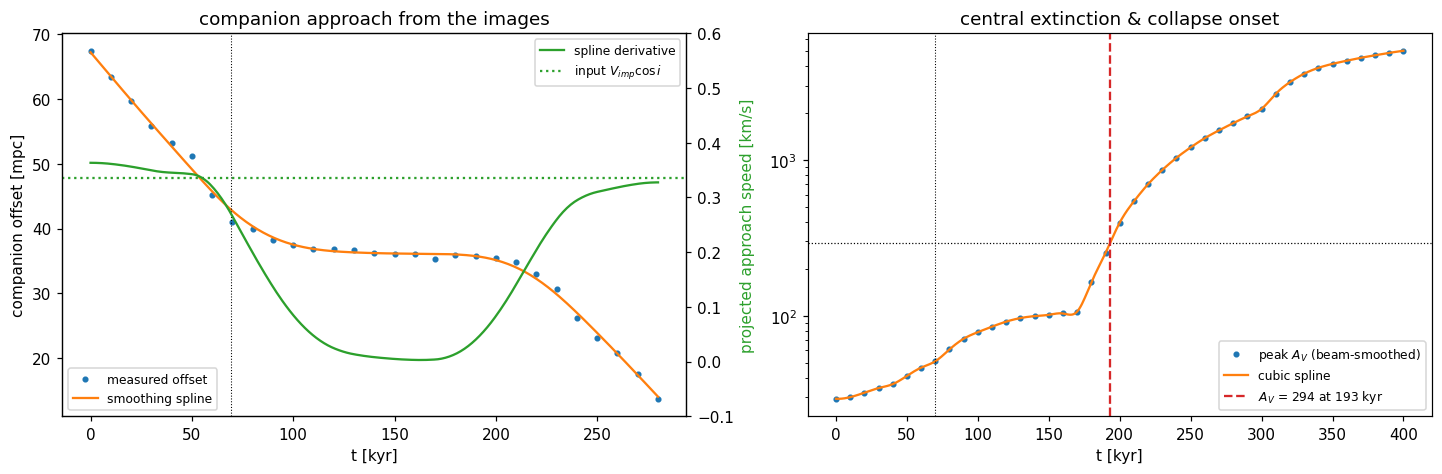

In [16]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.2), constrained_layout=True)

ok = np.isfinite(sep)
print(f"companion peak detected in {ok.sum()} of {len(T)} snapshots")
spl_sep = make_smoothing_spline(T[ok], sep[ok])
tt = np.linspace(T[ok][0], T[ok][-1], 300)
v_rec = -spl_sep.derivative()(tt) / KMS                           # km/s, approaching = positive
axs[0].plot(T[ok] * 1e3, sep[ok] * 1e3, "o", ms=3, label="measured offset")
axs[0].plot(tt * 1e3, spl_sep(tt) * 1e3, label="smoothing spline")
ax2 = axs[0].twinx()
ax2.plot(tt * 1e3, v_rec, c="C2", label="spline derivative")
ax2.axhline(KIN["v_imp"] * np.cos(inc), c="C2", ls=":", label=r"input $V_{imp}\cos i$")
ax2.set_ylabel("projected approach speed [km/s]", color="C2"); ax2.set_ylim(-0.1, 0.6)
axs[0].axvline(t_imp * 1e3, c="k", lw=0.7, ls=":")
axs[0].set_xlabel("t [kyr]"); axs[0].set_ylabel("companion offset [mpc]")
axs[0].legend(loc="lower left", fontsize=8); ax2.legend(loc="upper right", fontsize=8)
pre = tt < t_imp * 0.9
print(f"recovered pre-impact projected speed: {v_rec[pre].mean():.3f} km/s  "
      f"(input {KIN['v_imp']*np.cos(inc):.3f} km/s)")

av_peak = AV.reshape(len(T), -1).max(1)
cs = CubicSpline(T, np.log(av_peak))
AV_CRIT = round(10 * av_peak[0])                  # "runaway": ten times the initial peak
roots = [r for r in cs.solve(np.log(AV_CRIT), extrapolate=False) if r > t_imp]
axs[1].semilogy(T * 1e3, av_peak, "o", ms=3, label="peak $A_V$ (beam-smoothed)")
tt2 = np.linspace(0, T[-1], 400); axs[1].semilogy(tt2 * 1e3, np.exp(cs(tt2)), label="cubic spline")
axs[1].axhline(AV_CRIT, c="k", ls=":", lw=0.8)
if roots:
    axs[1].axvline(roots[0] * 1e3, c="C3", ls="--", label=f"$A_V$ = {AV_CRIT:.0f} at {roots[0]*1e3:.0f} kyr")
    print(f"peak A_V crosses {AV_CRIT:.0f} mag at t = {roots[0]*1e3:.0f} kyr, i.e. {(roots[0]-t_imp)*1e3:.0f} kyr after impact")
axs[1].axvline(t_imp * 1e3, c="k", lw=0.7, ls=":")
axs[1].set_xlabel("t [kyr]"); axs[1].legend(fontsize=8); axs[1].set_title("central extinction & collapse onset")
axs[0].set_title("companion approach from the images")
plt.show()

The spline derivative gives a pre-impact approach speed of $0.349\ \mathrm{km\,s^{-1}}$, 4% above the input $V_{\rm imp}\cos i = 0.335\ \mathrm{km\,s^{-1}}$. After impact the speed drops to zero while the companion is braked. It rises again after about 210 kyr, when the collapse front reaches the companion: with $r_f = c_s(t - t_{\rm imp})$ and the companion at about 36 mpc, the front arrives at $t \approx 69 + 147 = 216$ kyr.

The peak extinction grows slowly until about 170 kyr and then turns up sharply. It crosses ten times its initial value (294 mag) at $t = 193$ kyr, 124 kyr after impact.

### 6.5 Thin-plate spline of the velocity field

Observers usually fit a plane $v = v_0 + a\,\Delta x + b\,\Delta y$ to the centroid map of a globule (Goodman et al. 1993), which gives one gradient $|\nabla v| = \sqrt{a^2 + b^2}$ and one direction for the whole cloud. A thin-plate spline is also smooth but lets the gradient vary across the cloud. It minimises

$$
\sum_k \big(v_k - f(\mathbf x_k)\big)^2 + \lambda\iint\big(f_{xx}^2 + 2f_{xy}^2 + f_{yy}^2\big)\,dx\,dy \tag{10}
$$

(Wahba 1990) and is fitted to the masked $M_1$ map with `RBFInterpolator(kernel="thin_plate_spline")`. For solid-body rotation the gradient equals $|\boldsymbol\Omega|$ and is perpendicular to the rotation axis, so at $t = 0$ the fit in the core should recover the input values.

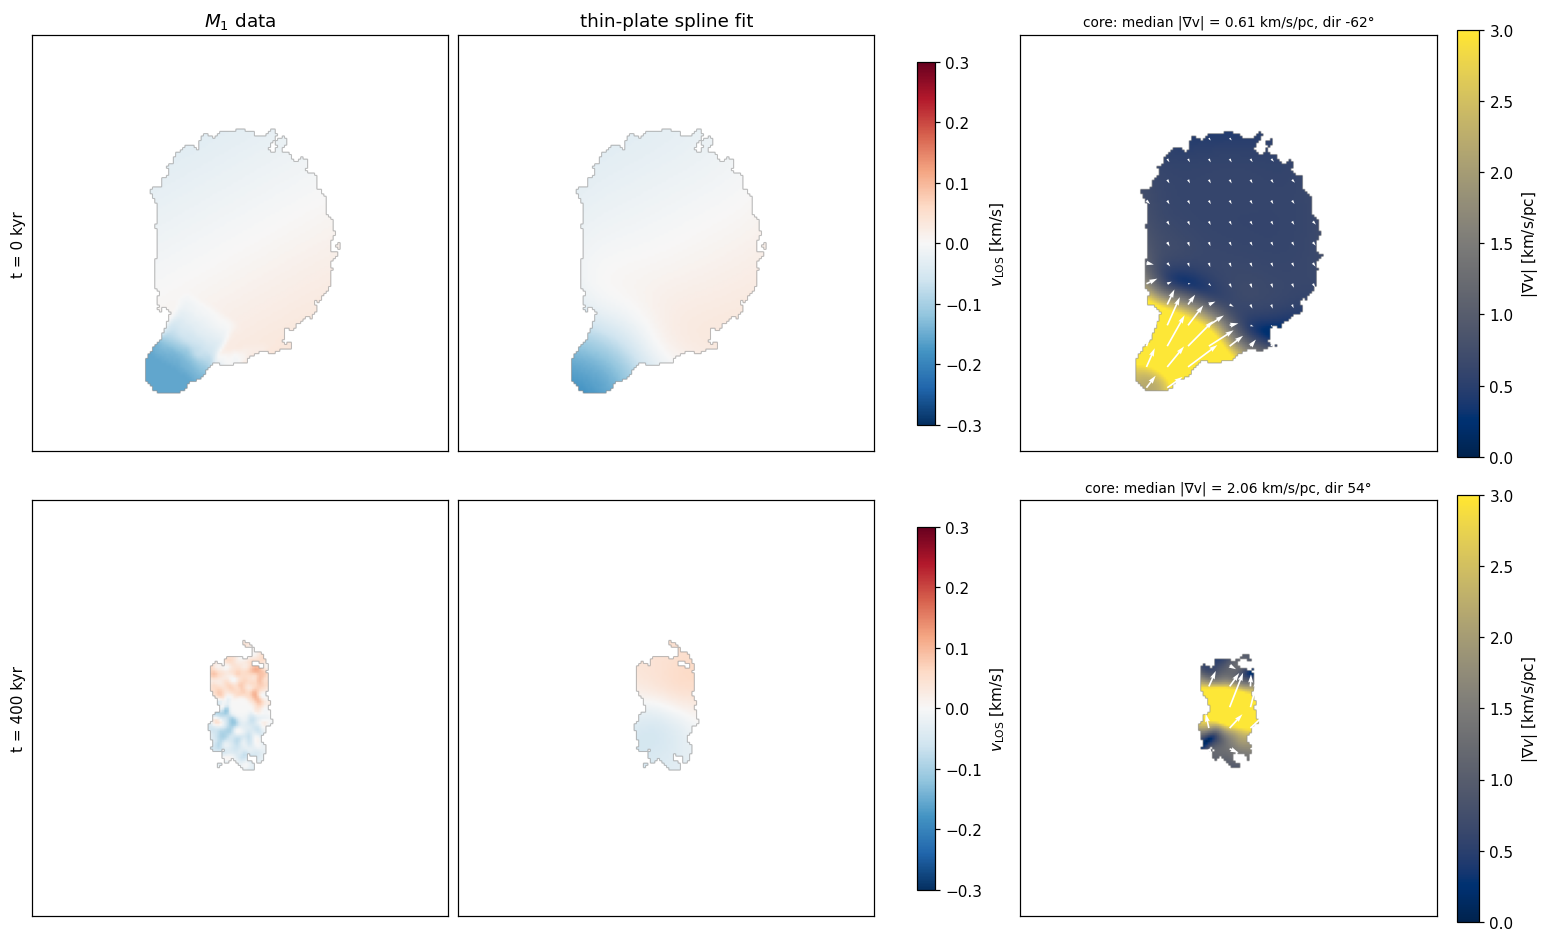

input rotation: |grad v| = 0.60 km/s/pc, direction -60° (perpendicular to the rotation axis at 30°)


In [17]:
def tps_velocity_field(X, V, av_min=3.0, n_max=2500, smoothing=0.02, seed=0):
    m1, _ = moment_maps(X, V, av_min=av_min)
    good = ~m1.mask
    pts = np.c_[XX[good], YY[good]]; vals = m1.data[good]
    sel = np.random.default_rng(seed).choice(len(pts), min(n_max, len(pts)), replace=False)
    tps = RBFInterpolator(pts[sel], vals[sel], kernel="thin_plate_spline", smoothing=smoothing)
    field = np.full(XX.shape, np.nan)
    field[good] = tps(np.c_[XX[good], YY[good]])
    gy, gx = np.gradient(field, PIX)
    return m1, field, gx, gy


fig, axs = plt.subplots(2, 3, figsize=(14, 8.5), constrained_layout=True)
for row, i in enumerate([0, len(T) - 1]):
    m1, f, gx, gy = tps_velocity_field(XS[i], VS[i])
    a = axs[row, 0].imshow(m1, extent=EXTENT, cmap="RdBu_r", vmin=-0.3, vmax=0.3)
    axs[row, 1].imshow(f, extent=EXTENT, cmap="RdBu_r", vmin=-0.3, vmax=0.3)
    g = np.hypot(gx, gy)
    b = axs[row, 2].imshow(g, extent=EXTENT, cmap="cividis", vmin=0, vmax=3)
    st = 9
    axs[row, 2].quiver(XX[::st, ::st], YY[::st, ::st], gx[::st, ::st], gy[::st, ::st], color="w", scale=60, width=0.004)
    fig.colorbar(a, ax=axs[row, :2], label=r"$v_{\rm LOS}$ [km/s]", shrink=0.85)
    fig.colorbar(b, ax=axs[row, 2], label=r"$|\nabla v|$ [km/s/pc]")
    core_mask = np.hypot(XX - c0[0], YY - c0[1]) < 0.03
    gmean = np.nanmedian(g[core_mask]); pa = np.degrees(np.arctan2(np.nanmedian(gy[core_mask]), np.nanmedian(gx[core_mask])))
    axs[row, 0].set_ylabel(f"t = {T[i]*1e3:.0f} kyr")
    axs[row, 2].set_title(f"core: median |∇v| = {gmean:.2f} km/s/pc, dir {pa:.0f}°", fontsize=9)
    for ax in axs[row]:
        ax.set_xticks([]); ax.set_yticks([])
axs[0, 0].set_title("$M_1$ data"); axs[0, 1].set_title("thin-plate spline fit")
plt.show()
# v_LOS = -(Omega x r)_z = Omega_y x - Omega_x y  ->  grad v_LOS = (Omega_y, -Omega_x)
g_true = np.r_[Omega_vec[1], -Omega_vec[0]]
print(f"input rotation: |grad v| = {np.hypot(*g_true):.2f} km/s/pc, direction "
      f"{np.degrees(np.arctan2(g_true[1], g_true[0])):.0f}° (perpendicular to the rotation axis at {KIN['rot_pa_deg']:.0f}°)")

At $t = 0$ the thin-plate spline gives a median gradient of $0.61\ \mathrm{km\,s^{-1}\,pc^{-1}}$ in the core at $-62^\circ$, against the input $0.60\ \mathrm{km\,s^{-1}\,pc^{-1}}$ at $-60^\circ$. This is within the range of 0.3 to 4 $\mathrm{km\,s^{-1}\,pc^{-1}}$ that Goodman et al. (1993) found for dense cores.

At 400 kyr the fitted gradient is $2.06\ \mathrm{km\,s^{-1}\,pc^{-1}}$ at $54^\circ$. $\boldsymbol\Omega$ is fixed and the companion stopped long before, so the extra gradient must come from the infall. In the small, elongated remnant the infall no longer cancels along the line of sight, probably because the companion and tail gas started behind the core. A single-plane fit would read this as faster rotation.

## 7. Export for ParaView

Every 4th snapshot is written to HDF5 in a Gadget/Arepo-style layout (`PartType0/Coordinates`, `Velocities`, `Masses`, `ComponentID`, `Weight`). The file `b68_snapshots/b68_evolution.xdmf` joins them into one time series that ParaView opens with the Xdmf3 reader.

In [18]:
EXPORT, EVERY = True, 4


def xdmf_item(fname, path, arr):
    # XDMF reference to one HDF5 dataset; type and size are taken from the array
    kind = "Int" if np.issubdtype(arr.dtype, np.integer) else "Float"
    dims = " ".join(map(str, arr.shape))
    return (f'<DataItem Dimensions="{dims}" NumberType="{kind}" Precision="{arr.dtype.itemsize}" '
            f'Format="HDF">{fname}:{path}</DataItem>')


if EXPORT:
    try:
        import h5py, os
        out = "b68_snapshots"
        os.makedirs(out, exist_ok=True)
        grids = []
        for j, i in enumerate(range(0, len(T), EVERY)):
            fname = f"snap_{j:03d}.hdf5"
            data = {"Coordinates": XS[i], "Velocities": VS[i], "Masses": np.full(NPART, M_P),
                    "ComponentID": comp.astype(np.int32), "Weight": w}
            with h5py.File(os.path.join(out, fname), "w") as f:
                hd = f.create_group("Header"); hd.attrs["Time_Myr"] = T[i]; hd.attrs["NumPart"] = NPART
                g = f.create_group("PartType0")
                for k, v in data.items():
                    g[k] = v
            attrs = "\n".join(
                f'      <Attribute Name="{k}" AttributeType="{"Vector" if v.ndim == 2 else "Scalar"}" Center="Node">'
                f'{xdmf_item(fname, "/PartType0/" + k, v)}</Attribute>'
                for k, v in data.items() if k != "Coordinates")
            grids.append(
                f'    <Grid Name="snap_{j:03d}" GridType="Uniform">\n'
                f'      <Time Value="{T[i]:.4f}"/>\n'
                f'      <Topology TopologyType="Polyvertex" NumberOfElements="{NPART}" NodesPerElement="1"/>\n'
                f'      <Geometry GeometryType="XYZ">{xdmf_item(fname, "/PartType0/Coordinates", data["Coordinates"])}</Geometry>\n'
                f'{attrs}\n    </Grid>')
        with open(os.path.join(out, "b68_evolution.xdmf"), "w") as f:
            f.write('<?xml version="1.0" ?>\n<Xdmf Version="3.0">\n<Domain>\n'
                    '  <Grid Name="B68" GridType="Collection" CollectionType="Temporal">\n'
                    + "\n".join(grids) + "\n  </Grid>\n</Domain>\n</Xdmf>\n")
        print(f"wrote {len(grids)} snapshots and b68_evolution.xdmf to {out}/")
    except ImportError:
        print("h5py is not installed: pip install h5py")

h5py is not installed: pip install h5py


## 8. Conclusion

* The flat silhouette of B68 was turned into a 3-D cloud of 75 676 particles with a Bonnor-Ebert profile ($\xi_{\max} = 6.9$), a sub-critical companion, $R = 0.0606$ pc and $M = 2.1\,M_\odot$.
* With the prescribed velocity field (companion impact, tail compression, inside-out infall and slow rotation) the companion hits the core at 69 kyr, and the central extinction passes ten times its initial value 124 kyr after impact. This is the same order as the $2\times10^5$ yr of Burkert & Alves (2009), but only because the timescales follow from the chosen parameters.
* Infall cannot be seen in the velocity centroid $M_1$, because the front and back of the cloud cancel. It is clear in the line width $M_2$ and in the spectra, which become double-peaked with a peak separation of about $0.8\ \mathrm{km\,s^{-1}}$ by 400 kyr.
* Splines turn the noisy maps into quantities that can be followed in time: the curvature and circularity of the outline, the companion peak and the neck, the slope of the radial profile and a smooth velocity field. The slope at a fixed radius is the least reliable of them.
* From the images alone, the spline derivative gives a projected approach speed of 0.349 km/s (input 0.335 km/s), and the thin-plate spline gives a rotation gradient of 0.61 km/s/pc at $-62^\circ$ (input 0.60 km/s/pc at $-60^\circ$).

### Limitations and next steps

The model is kinematic. It leaves out pressure, shocks, the compression wave from the collision and angular-momentum conservation during collapse, and the infall speed is a fraction of the escape speed rather than a solution of the Euler equations. The results depend mainly on the inclination $i$, on $A_\infty$ and $\tau_{\rm ramp}$ (how violent the collapse is), on $\Omega$ (the velocity gradient) and on the depth ratio of the core (Section 2.2). Next steps:

1. Fit a projected Bonnor-Ebert profile to the spline of Section 6.3 and follow $\xi_{\max}$ in time.
2. Replace the prescribed infall by the gravitational acceleration from $M(<r)$, which turns the model into a 1-D Lagrangian dynamics problem, and compare the two.
3. Use the positions and velocities of the first snapshot (`XS[0]`, `VS[0]`) as initial conditions for a full hydrodynamic simulation.

## 9. Bibliography

1. J. F. Alves, C. J. Lada, E. A. Lada (2001), "Internal structure of a cold dark molecular cloud inferred from the extinction of background starlight", *Nature* 409, 159-161.
2. A. Burkert, J. Alves (2009), "The inevitable future of the starless core Barnard 68", *The Astrophysical Journal* 695, 1308-1314.
3. C. J. Lada, E. A. Bergin, J. F. Alves, T. L. Huard (2003), "The dynamical state of Barnard 68: a thermally supported, pulsating dark cloud", *The Astrophysical Journal* 586, 286-295.
4. R. Ebert (1955), "Über die Verdichtung von H I-Gebieten", *Zeitschrift für Astrophysik* 37, 217-232.
5. W. B. Bonnor (1956), "Boyle's law and gravitational instability", *Monthly Notices of the Royal Astronomical Society* 116, 351-359.
6. F. H. Shu (1977), "Self-similar collapse of isothermal spheres and star formation", *The Astrophysical Journal* 214, 488-497.
7. A. A. Goodman, P. J. Benson, G. A. Fuller, P. C. Myers (1993), "Dense cores in dark clouds. VIII. Velocity gradients", *The Astrophysical Journal* 406, 528-547.
8. R. C. Bohlin, B. D. Savage, J. F. Drake (1978), "A survey of interstellar H I from L-alpha absorption measurements. II", *The Astrophysical Journal* 224, 132-142.
9. J. A. Cardelli, G. C. Clayton, J. S. Mathis (1989), "The relationship between infrared, optical, and ultraviolet extinction", *The Astrophysical Journal* 345, 245-256.
10. W. Steffen, N. Koning, S. Wenger, C. Morisset, M. Magnor (2011), "Shape: a 3D modeling tool for astrophysics", *IEEE Transactions on Visualization and Computer Graphics* 17, 454-465.
11. P. Dierckx, *Curve and Surface Fitting with Splines*, Oxford University Press, 1993.
12. G. Wahba, *Spline Models for Observational Data*, SIAM, 1990.
13. W. H. Press, S. A. Teukolsky, W. T. Vetterling, B. P. Flannery, *Numerical Recipes: The Art of Scientific Computing*, 3rd ed., Cambridge University Press, 2007, Ch. 17.
14. C. R. Harris et al. (2020), "Array programming with NumPy", *Nature* 585, 357-362.
15. P. Virtanen et al. (2020), "SciPy 1.0: fundamental algorithms for scientific computing in Python", *Nature Methods* 17, 261-272.
16. J. D. Hunter (2007), "Matplotlib: a 2D graphics environment", *Computing in Science & Engineering* 9, 90-95.